<div class="alert alert-block alert-warning">

# <p style="text-align: center;">Audio Localisation Theoretical Modelling</p>


## Aims
The aims of this model are:
- to test theoretical models on determining the direction of audio using signal processing
- to test numerical models to implement theoretical models
- to prove the feasibility of models to be implemented on a FPGA or similar device


## Introduction
The concept audio localisation is something that the human body automatically performs to enable us to perceive the direction and approximate distance of a sound. The plan is to mimic this behaviour using an FPGA to learn about practical digital signal processing (DSP). Most of the exact theorerical concepts are obtained from Carnegie Mellon University(CMU).

Sound Localisation Presentation (CMU): https://www.cs.cmu.edu/~lewicki/cp-s08/sound-localization1.pdf

Sound Localisation Paper (CMU): https://www.cs.cmu.edu/~rms/BinauralWeb/papers/SternWangBrownChapter.pdf 

In [1]:
import numpy as np
import pandas as pd
import scipy
from scipy.io import wavfile
from scipy.fft import fft, ifft, fftshift
from scipy.sparse import csr_matrix, coo_matrix, csc_matrix, dok_matrix, lil_matrix
import matplotlib.pyplot as plt
import random
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

## Input Signal Generation
First we need sample signals to test different analysis techniques. As a Fourier Transform (FT) will be performed, a sinusoid will be used to provide an easier time interpreting the affects of different situations.

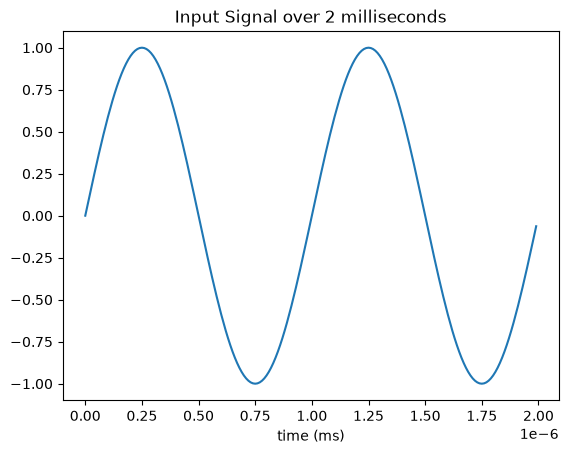

In [4]:
sampling_frequency = 100*10**3
sampling_period = 1/sampling_frequency
time = np.arange(0, 1+sampling_period, sampling_period)

signal_frequency = 1000; # Frequency in Hz
sinusoid_1000hz = np.sin(2*np.pi*signal_frequency*time)

# The window constant is defined in seconds
window = int(0.002 * sampling_frequency) # 2ms
plt.plot(time[:window]/1000, sinusoid_1000hz[:window])
plt.xlabel("time (ms)")
plt.xscale("linear")
plt.title("Input Signal over 2 milliseconds")
plt.show()

## Observing ITD
Two techniques to determine Interaural Time Difference (ITD). The first method is the one proposed in a CMU slideshow, This is mainly be computing the Cross-correlation of the two signals, and is defined by the function.

$Cross\space Correlation = \frac{1}{Z} \int_{-\infty}^{\infty}x(\tau)y(t-\tau)d\tau$

Where Z is defined as:

$Z=\int_{-\infty}^{\infty}x(\tau)y(\tau)d\tau$

However, this is defined in continous time. If we were to take a discrete time version of this, the integral will need to be replaced with a summation

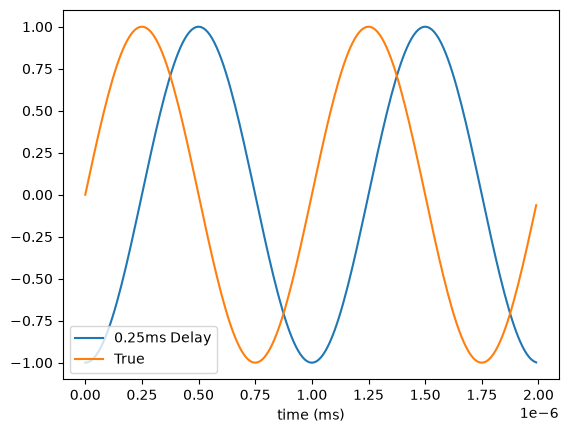

-0.00025


In [29]:
exact_delay = 0.25/1000 # This should be a 0.25ms delay
delayed_sinusoid_1000hz = np.sin(2*np.pi*signal_frequency*(time - exact_delay))

Z = np.sum(delayed_sinusoid_1000hz * sinusoid_1000hz)
cross_correlation = 1/Z * scipy.signal.convolve(sinusoid_1000hz, delayed_sinusoid_1000hz)

# The 0 point is in the middle, not the side
cross_correlation_peak = np.argmax(cross_correlation) - (len(cross_correlation) // 2)
computed_time_delay = cross_correlation_peak * sampling_period

plt.plot(time[:window]/1000, delayed_sinusoid_1000hz[:window], label=f"{exact_delay*1000:.2f}ms Delay")
plt.plot(time[:window]/1000, sinusoid_1000hz[:window], label="True")
plt.xlabel("time (ms)")
plt.legend()
plt.show()

print(computed_time_delay)

As we can see this matches our expectations. However, I want to test out a frequency approach

In [60]:
def fft_plot(N, X_k, units="rad", Fs=50, title="FFT", merge="False"):
    k = np.arange(-np.floor(N / 2), N - np.floor(N / 2))
    
    plt.figure(figsize=(12, 5))
    plt.suptitle(title)

    match units:
        case "rad":
            omega = k * (2 * np.pi / N)

            plt.subplot(1,2,1)
            plt.title("Frequency vs Magnitude")
            plt.stem(omega, fftshift(np.abs(X_k)), markerfmt=' ')
            plt.xlabel("Frequency (rad/s)")
            plt.ylabel("Magnitude")

            plt.subplot(1,2,2)
            plt.title("Frequency vs Phase")
            plt.stem(omega, fftshift(np.angle(X_k)), markerfmt=' ')
            plt.xlabel("Frequency (rad/s)")
            plt.ylabel("Phase")

        case "hz":
            omega = k * (Fs / N)

            if merge == True:
                plt.stem(omega, fftshift(np.real(X_k)), markerfmt=' ')
                plt.xlabel("Frequency (Hz)")
                plt.ylabel("FFT")
            else:
                plt.subplot(1,2,1)
                plt.title("Frequency vs Magnitude")
                plt.stem(omega, fftshift(np.abs(X_k)), markerfmt=' ')
                plt.xlabel("Frequency (Hz)")
                plt.ylabel("Magnitude")

                plt.subplot(1,2,2)
                plt.title("Frequency vs Phase")
                plt.plot(omega, fftshift(np.angle(X_k)))
                plt.xlabel("Frequency (Hz)")
                plt.ylabel("Phase")            

        case _:

            plt.subplot(1,2,1)
            plt.title("Frequency vs Magnitude")
            plt.stem(k, fftshift(np.abs(X_k)), markerfmt=' ')
            plt.xlabel("Frequency")
            plt.ylabel("Magnitude")
            
            plt.subplot(1,2,2)
            plt.title("Frequency vs Phase")
            plt.stem(k, fftshift(np.angle(X_k)), markerfmt=' ')
            plt.xlabel("Frequency")
            plt.ylabel("Phase")

    plt.tight_layout()
    plt.show()

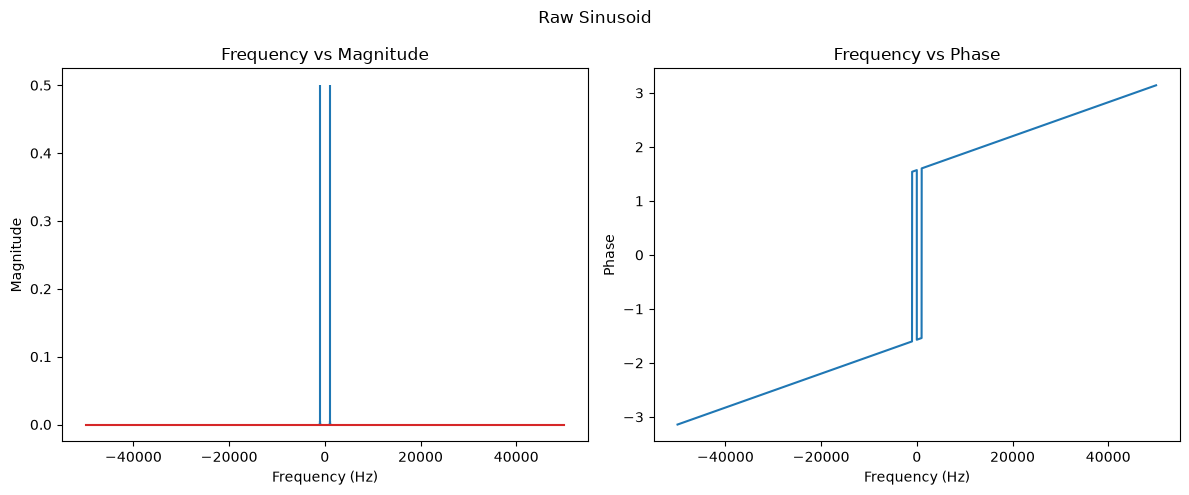

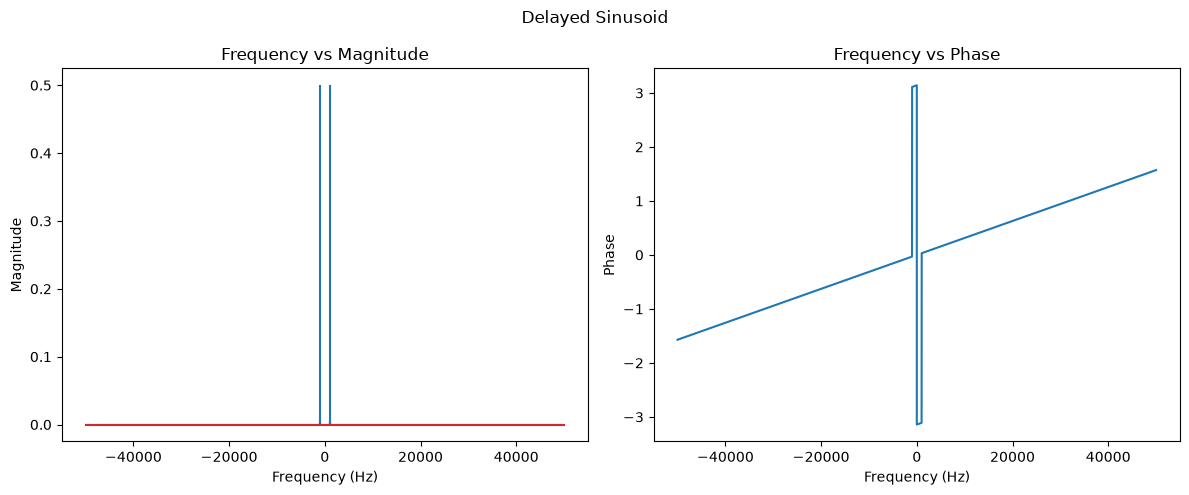

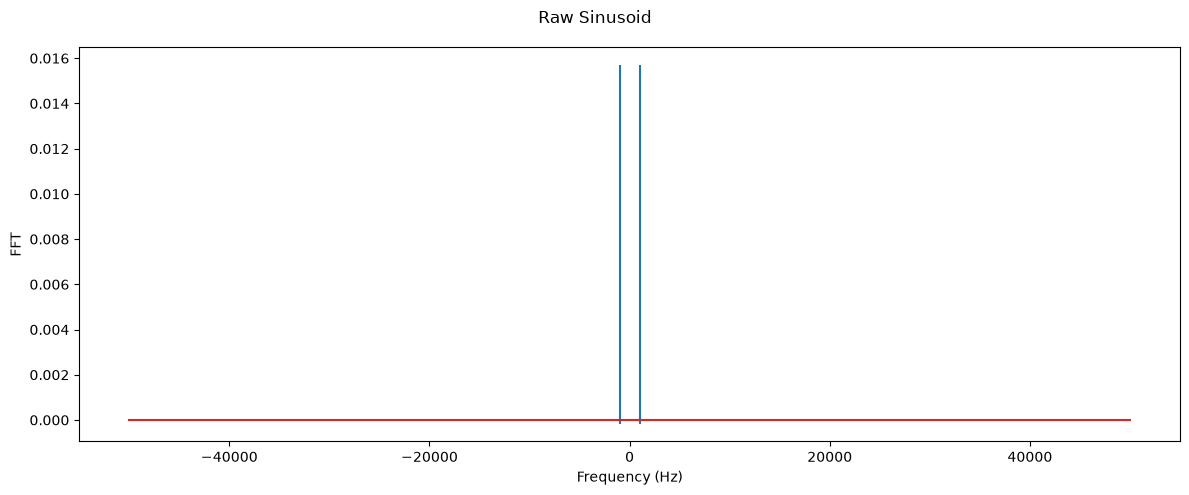

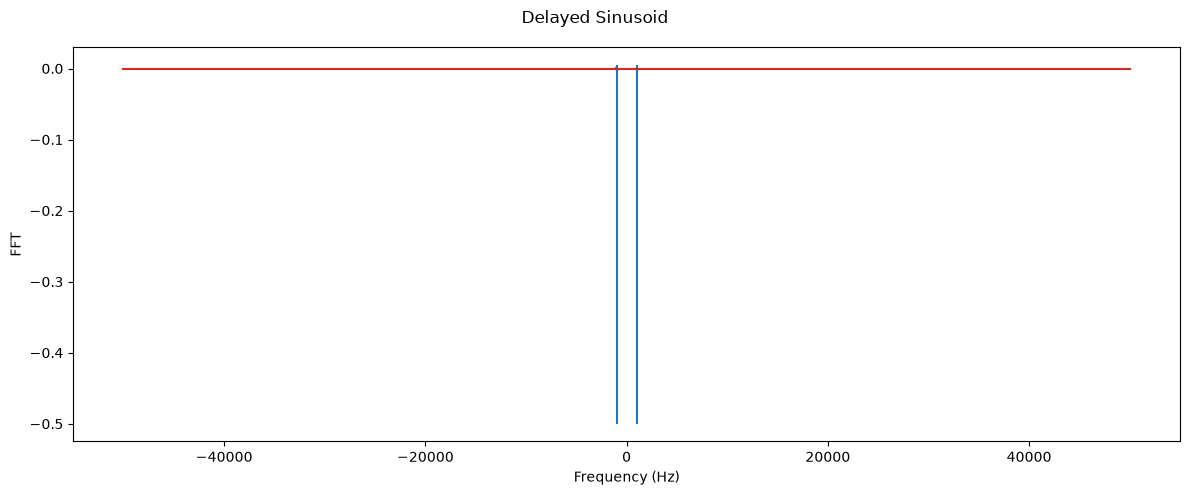

In [62]:
raw_sinusoid_len = len(sinusoid_1000hz)
raw_sinusoid_fft = 1/raw_sinusoid_len * fft(sinusoid_1000hz)
fft_plot(raw_sinusoid_len, raw_sinusoid_fft, units="hz", Fs=sampling_frequency, title="Raw Sinusoid")

delayed_sinusoid_len = len(delayed_sinusoid_1000hz)
delayed_sinusoid_fft = 1/delayed_sinusoid_len * fft(delayed_sinusoid_1000hz)
fft_plot(delayed_sinusoid_len, delayed_sinusoid_fft, units="hz", Fs=sampling_frequency, title="Delayed Sinusoid")

fft_plot(raw_sinusoid_len, raw_sinusoid_fft, units="hz", Fs=sampling_frequency, title="Raw Sinusoid", merge=True)
fft_plot(delayed_sinusoid_len, delayed_sinusoid_fft, units="hz", Fs=sampling_frequency, title="Delayed Sinusoid", merge=True)